# How variable is the temperature? Daily, day-over-day and yearly swings in 40 cities, 1980-2025

**Questions**
1. How much does temperature swing *within a day* (diurnal range)?
2. How much does it jump *from one day to the next*?
3. How big is the *yearly* swing from coldest to hottest weeks?
4. Have these changed since 1980?

**Data:** [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api), ERA5 reanalysis (~25 km grid, hourly). Same model for every city, so comparisons are not distorted by different instruments or station gaps.

**This notebook so far:** 1) config, 2) cached fetch, 3) hourly to daily table, 4) sanity check, 5) metrics (simple version, no anomalies), 6) city summary table. 7) visuals, 8) trends over 1980-2025, 9) validation against weather stations.

## 1. Config

In [1]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START_YEAR, END_YEAR = 1980, 2025          # full years only
CHUNK_YEARS = 5                            # years per API request
HOURLY_VARS = ["temperature_2m", "apparent_temperature"]   # add "relative_humidity_2m" if you want it
API_URL = "https://archive-api.open-meteo.com/v1/archive"

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
DAILY_DIR = DATA_DIR / "daily"
for d in (RAW_DIR, DAILY_DIR):
    d.mkdir(parents=True, exist_ok=True)

### City list
`tz` is the IANA timezone, used to convert UTC hours to *local* time (so "hour of day" is right and the daily max/min fall on the local calendar day).
`group` is a rough climate type, used later to colour and facet charts.

In [3]:
cities = [
    # name, lat, lon, tz, group
    ("Mumbai", 19.076, 72.878, "Asia/Kolkata", "Tropical"),
    ("Singapore", 1.352, 103.820, "Asia/Singapore", "Tropical"),
    ("Lagos", 6.524, 3.379, "Africa/Lagos", "Tropical"),
    ("Kinshasa", -4.442, 15.266, "Africa/Kinshasa", "Tropical"),
    ("Dhaka", 23.810, 90.412, "Asia/Dhaka", "Tropical"),
    ("Kolkata", 22.573, 88.364, "Asia/Kolkata", "Tropical"),
    ("Manila", 14.600, 120.984, "Asia/Manila", "Tropical"),
    ("Jakarta", -6.209, 106.846, "Asia/Jakarta", "Tropical"),
    ("Rio de Janeiro", -22.907, -43.173, "America/Sao_Paulo", "Tropical"),

    ("Nairobi", -1.286, 36.817, "Africa/Nairobi", "Highland"),
    ("Mexico City", 19.433, -99.133, "America/Mexico_City", "Highland"),
    ("Bangalore", 12.972, 77.594, "Asia/Kolkata", "Highland"),

    ("Dubai", 25.205, 55.271, "Asia/Dubai", "Arid"),
    ("Phoenix", 33.449, -112.074, "America/Phoenix", "Arid"),
    ("Cairo", 30.044, 31.236, "Africa/Cairo", "Arid"),
    ("Karachi", 24.861, 67.010, "Asia/Karachi", "Arid"),

    ("Delhi", 28.614, 77.209, "Asia/Kolkata", "Humid subtropical"),
    ("Tokyo", 35.690, 139.692, "Asia/Tokyo", "Humid subtropical"),
    ("Osaka", 34.694, 135.502, "Asia/Tokyo", "Humid subtropical"),
    ("Shanghai", 31.230, 121.474, "Asia/Shanghai", "Humid subtropical"),
    ("Guangzhou", 23.129, 113.264, "Asia/Shanghai", "Humid subtropical"),
    ("Chongqing", 29.563, 106.552, "Asia/Shanghai", "Humid subtropical"),
    ("Sao Paulo", -23.551, -46.633, "America/Sao_Paulo", "Humid subtropical"),
    ("Buenos Aires", -34.604, -58.382, "America/Argentina/Buenos_Aires", "Humid subtropical"),
    ("Sydney", -33.869, 151.209, "Australia/Sydney", "Humid subtropical"),
    ("Istanbul", 41.008, 28.978, "Europe/Istanbul", "Humid subtropical"),
    ("Dallas", 32.777, -96.797, "America/Chicago", "Humid subtropical"),

    ("Seattle", 47.606, -122.332, "America/Los_Angeles", "Maritime temperate"),
    ("London", 51.507, -0.128, "Europe/London", "Maritime temperate"),
    ("Los Angeles", 34.052, -118.244, "America/Los_Angeles", "Maritime temperate"),
    ("Cape Town", -33.925, 18.424, "Africa/Johannesburg", "Maritime temperate"),

    ("New York", 40.713, -74.006, "America/New_York", "Continental"),
    ("Toronto", 43.653, -79.383, "America/Toronto", "Continental"),
    ("Chicago", 41.878, -87.630, "America/Chicago", "Continental"),
    ("Minneapolis", 44.978, -93.265, "America/Chicago", "Continental"),
    ("Denver", 39.739, -104.990, "America/Denver", "Continental"),
    ("Moscow", 55.756, 37.617, "Europe/Moscow", "Continental"),
    ("Beijing", 39.904, 116.407, "Asia/Shanghai", "Continental"),
    ("Seoul", 37.567, 126.978, "Asia/Seoul", "Continental"),

    ("Reykjavik", 64.147, -21.942, "Atlantic/Reykjavik", "Subpolar"),
]
cities = pd.DataFrame(cities, columns=["city", "lat", "lon", "tz", "group"])
cities["slug"] = cities["city"].str.lower().str.replace(" ", "_")
print(len(cities), "cities")
cities.groupby("group")["city"].apply(", ".join)

40 cities


group
Arid                                     Dubai, Phoenix, Cairo, Karachi
Continental           New York, Toronto, Chicago, Minneapolis, Denve...
Highland                                Nairobi, Mexico City, Bangalore
Humid subtropical     Delhi, Tokyo, Osaka, Shanghai, Guangzhou, Chon...
Maritime temperate              Seattle, London, Los Angeles, Cape Town
Subpolar                                                      Reykjavik
Tropical              Mumbai, Singapore, Lagos, Kinshasa, Dhaka, Kol...
Name: city, dtype: str

## 2. Fetch (cached and resumable)

- One request per city per 5-year chunk, saved to `data/raw/<city>_<start>_<end>.parquet`. Existing files are skipped, so you can re-run the cell any time.
- Times are requested in **UTC** and converted to local time in step 3. That avoids duplicated or missing hours around daylight-saving changes.
- The free API has per-minute, per-hour and per-day limits, and bigger requests count for more. If the daily limit is hit, the loop stops cleanly. Just re-run the next day and it carries on where it left off. Check Open-Meteo's docs for current limits.
- `data/raw/_grid_info.csv` records the grid point and elevation ERA5 actually used for each city, which is worth a glance for coastal cities like Mumbai.

In [4]:
class DailyLimitReached(Exception):
    pass


def year_chunks(start_year, end_year, size):
    y = start_year
    while y <= end_year:
        yield y, min(y + size - 1, end_year)
        y += size


def fetch_chunk(row, y0, y1, max_retries=6):
    params = {
        "latitude": row.lat,
        "longitude": row.lon,
        "start_date": f"{y0}-01-01",
        "end_date": f"{y1}-12-31",
        "hourly": ",".join(HOURLY_VARS),
        "timezone": "GMT",
        "models": "era5",
    }
    for attempt in range(max_retries):
        r = requests.get(API_URL, params=params, timeout=120)
        if r.status_code == 200:
            return r.json()
        reason = ""
        try:
            reason = r.json().get("reason", "")
        except Exception:
            pass
        if r.status_code == 429:
            if "daily" in reason.lower():
                raise DailyLimitReached(reason)
            wait = 65 * (attempt + 1)          # minute/hour limit: wait and retry
            print(f"  rate limited ({reason or '429'}), sleeping {wait}s")
            time.sleep(wait)
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {reason or r.text[:200]}")
    raise RuntimeError("too many retries")


def fetch_all(cities_df, pause=0.5):
    grid_rows = []
    for row in cities_df.itertuples():
        for y0, y1 in year_chunks(START_YEAR, END_YEAR, CHUNK_YEARS):
            path = RAW_DIR / f"{row.slug}_{y0}_{y1}.parquet"
            if path.exists():
                continue
            print(f"{row.city} {y0}-{y1}")
            j = fetch_chunk(row, y0, y1)
            df = pd.DataFrame(j["hourly"])
            df["time"] = pd.to_datetime(df["time"], utc=True)
            df.to_parquet(path, index=False)
            grid_rows.append({"city": row.city, "req_lat": row.lat, "req_lon": row.lon,
                              "grid_lat": j.get("latitude"), "grid_lon": j.get("longitude"),
                              "elevation_m": j.get("elevation")})
            time.sleep(pause)
    if grid_rows:
        info_path = RAW_DIR / "_grid_info.csv"
        new = pd.DataFrame(grid_rows).drop_duplicates("city")
        if info_path.exists():
            old = pd.read_csv(info_path)
            new = pd.concat([old, new]).drop_duplicates("city", keep="first")
        new.to_csv(info_path, index=False)


try:
    fetch_all(cities)
    print("Fetch complete.")
except DailyLimitReached as e:
    print("Daily API limit reached. Re-run this cell later to resume.\n", e)

Fetch complete.


## 3. Hourly to daily table (local time)

For each city: stitch chunks together, convert UTC to local time, then summarise each local calendar day.
Days with fewer than 23 hourly values (the first and last day can be partial after the timezone shift) are dropped.
DST days have 23 or 25 hours, which is why the threshold is 23 rather than 24.

In [5]:
def build_daily(row):
    files = sorted(RAW_DIR.glob(f"{row.slug}_*.parquet"))
    if not files:
        return None
    h = pd.concat([pd.read_parquet(f) for f in files]).drop_duplicates("time").sort_values("time")
    h["local"] = h["time"].dt.tz_convert(row.tz)
    h["date"] = h["local"].dt.tz_localize(None).dt.normalize()

    g = h.groupby("date")
    daily = pd.DataFrame({
        "n_hours": g["temperature_2m"].count(),
        "tmean": g["temperature_2m"].mean(),
        "tmax": g["temperature_2m"].max(),
        "tmin": g["temperature_2m"].min(),
        "tstd_hourly": g["temperature_2m"].std(),
    })
    if "apparent_temperature" in h:
        daily["app_mean"] = g["apparent_temperature"].mean()
        daily["app_max"] = g["apparent_temperature"].max()
        daily["app_min"] = g["apparent_temperature"].min()
    daily = daily[daily["n_hours"] >= 23].copy()
    daily["dtr"] = daily["tmax"] - daily["tmin"]          # diurnal temperature range
    daily.insert(0, "city", row.city)
    return daily.reset_index()


frames = [build_daily(r) for r in cities.itertuples()]
daily = pd.concat([f for f in frames if f is not None], ignore_index=True)
daily = daily.merge(cities[["city", "group"]], on="city")
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily.to_parquet(DAILY_DIR / "all_cities_daily.parquet", index=False)
print(daily.shape)
daily.head()

(672044, 14)


,date,city,n_hours,tmean,tmax,tmin,tstd_hourly,app_mean,app_max,app_min,dtr,group,year,month
0,1980-01-02,Mumbai,24,22.987500,25.9,19.7,1.884101,24.779167,28.1,20.1,6.2,Tropical,1980,1
1,1980-01-03,Mumbai,24,21.770833,26.3,17.8,3.030781,21.783333,26.7,18.2,8.5,Tropical,1980,1
2,1980-01-04,Mumbai,24,22.691667,28.6,17.5,3.837562,23.429167,31.0,17.3,11.1,Tropical,1980,1
3,1980-01-05,Mumbai,24,23.525000,28.4,18.7,3.313641,25.858333,30.5,20.5,9.7,Tropical,1980,1
4,1980-01-06,Mumbai,24,24.891667,29.9,19.7,3.641299,27.304167,32.9,21.9,10.2,Tropical,1980,1


## 4. Sanity check

Before computing anything fancy, check coverage and that the quick results match intuition
(Mumbai and Singapore low diurnal range; Phoenix, Denver and Dubai high; Seattle somewhere in between).

Cities with <99.9% coverage:
Empty DataFrame
Columns: [days, pct_complete]
Index: []


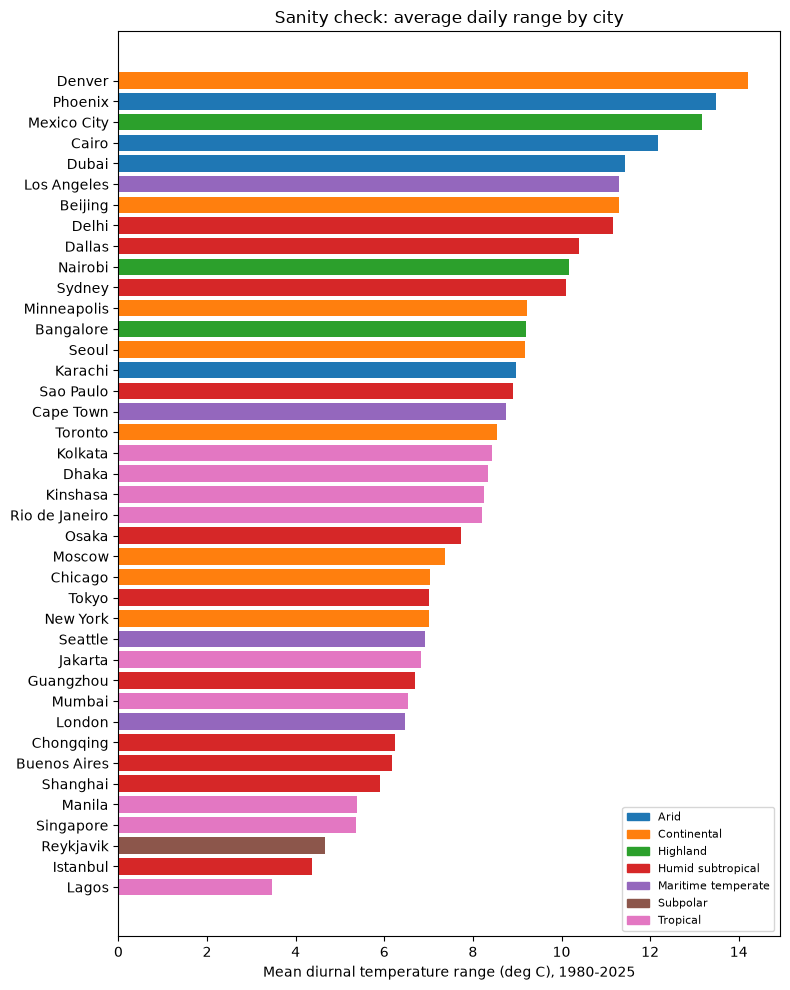

In [6]:
expected_days = (pd.Timestamp(f"{END_YEAR}-12-31") - pd.Timestamp(f"{START_YEAR}-01-01")).days + 1
cov = daily.groupby("city").size().rename("days").to_frame()
cov["pct_complete"] = (cov["days"] / expected_days * 100).round(2)
print("Cities with <99.9% coverage:")
print(cov[cov["pct_complete"] < 99.9])

mean_dtr = (daily.groupby(["group", "city"])["dtr"].mean()
            .reset_index().sort_values("dtr"))

fig, ax = plt.subplots(figsize=(8, 10))
palette = dict(zip(sorted(cities["group"].unique()), plt.cm.tab10.colors))
ax.barh(mean_dtr["city"], mean_dtr["dtr"], color=[palette[g] for g in mean_dtr["group"]])
ax.set_xlabel("Mean diurnal temperature range (deg C), 1980-2025")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), loc="lower right", fontsize=8)
ax.set_title("Sanity check: average daily range by city")
plt.tight_layout()
plt.show()

## 5. Metrics

Three scales, three metrics (plus "tail" variants):

| Scale | Primary | Variants |
|---|---|---|
| Within a day | Diurnal range = daily max - daily min | monthly profile |
| Day over day | Mean absolute change in the **daily high (tmax)** and the **daily low (tmin)**, abs(T(d) - T(d-1)) | 95th percentile of that change; days per year where the high or low changes by >=10 C within 2 days |
| Within a year | P95 - P5 of daily mean temp | std of daily means; extreme range (hottest hour - coldest hour); "feels-like" extreme range from apparent temperature |

**Why highs and lows, not the daily mean:** a warm afternoon and a cool night average out, so the daily mean hides the swings people actually feel ("30 C today, 15 C in two days" is about the high). Tracking tmax and tmin separately also shows whether a city's swings come from its days or its nights.

**A note on seasons:** the day-over-day numbers are raw changes, so they include a small amount of normal seasonal drift (spring warm-up, autumn cool-down). It adds a similar small amount to every city, so city-to-city comparisons and the big-swing counts are largely unaffected.

In [7]:
d = daily.sort_values(["city", "date"]).reset_index(drop=True)

SWING_VARS = ["tmax", "tmin"]   # swings are measured on daily highs and daily lows
SWING_C = 10                    # threshold (deg C) for a "big swing within 2 days"

# only compare days that are consecutive on the calendar
gap1 = d.groupby("city")["date"].diff().dt.days
gap2 = d.groupby("city")["date"].diff(2).dt.days

for v in SWING_VARS:
    gv = d.groupby("city")[v]
    d[f"{v}_d1"] = gv.diff().where(gap1 == 1)                    # today minus yesterday
    d[f"{v}_d2"] = (d[v] - gv.shift(2)).where(gap2 == 2)         # today minus 2 days ago
    d[f"abs_{v}_d1"] = d[f"{v}_d1"].abs()
    d[f"{v}_swing48"] = (d[f"{v}_d2"].abs() >= SWING_C).astype(int)

# a day counts as a big-swing day if either the high or the low moved >= SWING_C within 2 days
d["swing48_any"] = ((d["tmax_swing48"] + d["tmin_swing48"]) > 0).astype(int)
d[["city", "date", "tmax", "tmax_d1", "tmax_d2", "tmin", "tmin_d1", "tmin_d2"]].tail()

,city,date,tmax,tmax_d1,tmax_d2,tmin,tmin_d1,tmin_d2
672039,Toronto,2025-12-26,-3.0,-4.8,-6.8,-7.5,-0.5,-6.0
672040,Toronto,2025-12-27,-2.9,0.1,-4.7,-9.9,-2.4,-2.9
672041,Toronto,2025-12-28,0.7,3.6,3.7,-2.5,7.4,5.0
672042,Toronto,2025-12-29,8.6,7.9,11.5,-7.3,-4.8,2.6
672043,Toronto,2025-12-30,-4.1,-12.7,-4.8,-8.1,-0.8,-5.6


In [8]:
agg_spec = dict(
    dtr_mean=("dtr", "mean"),
    tmean_p05=("tmean", lambda s: s.quantile(0.05)),
    tmean_p95=("tmean", lambda s: s.quantile(0.95)),
    annual_std=("tmean", "std"),
    tmax_year=("tmax", "max"),
    tmin_year=("tmin", "min"),
    app_max_year=("app_max", "max"),
    app_min_year=("app_min", "min"),
)
for v in SWING_VARS:
    agg_spec[f"dod_abs_{v}"] = (f"abs_{v}_d1", "mean")                              # average day-to-day change
    agg_spec[f"dod_p95_{v}"] = (f"abs_{v}_d1", lambda s: s.quantile(0.95))          # 95th percentile (the big jumps)
    agg_spec[f"swing48_days_{v}"] = (f"{v}_swing48", "sum")                         # days with a >= SWING_C change in 2 days
agg_spec["swing48_days_any"] = ("swing48_any", "sum")

annual = d.groupby(["city", "year"]).agg(**agg_spec).reset_index()

annual["annual_p95_p5"] = annual["tmean_p95"] - annual["tmean_p05"]
annual["annual_extreme_range"] = annual["tmax_year"] - annual["tmin_year"]
annual["feels_like_extreme_range"] = annual["app_max_year"] - annual["app_min_year"]
annual = annual.merge(cities[["city", "group"]], on="city")

# monthly diurnal-range profile (city x month), for seasonal contrast later
dtr_month = d.groupby(["city", "month"])["dtr"].mean().unstack("month")

annual.to_parquet(DAILY_DIR / "annual_metrics.parquet", index=False)
d.to_parquet(DAILY_DIR / "daily_with_changes.parquet", index=False)
annual.head()

,city,year,dtr_mean,tmean_p05,tmean_p95,annual_std,tmax_year,tmin_year,app_max_year,app_min_year,...,dod_p95_tmax,swing48_days_tmax,dod_abs_tmin,dod_p95_tmin,swing48_days_tmin,swing48_days_any,annual_p95_p5,annual_extreme_range,feels_like_extreme_range,group
0,Bangalore,1980,9.757534,20.290000,26.805000,2.107378,36.4,12.0,39.3,10.9,...,2.50,0,0.735165,1.90,0,0,6.515000,24.4,28.4,Highland
1,Bangalore,1981,9.280548,19.040833,26.640833,2.166747,34.1,8.5,38.2,5.4,...,2.18,0,0.793699,2.20,0,0,7.600000,25.6,32.8,Highland
2,Bangalore,1982,9.536438,19.431667,26.788333,2.275129,33.9,12.6,36.4,11.7,...,2.18,0,0.705753,1.80,0,0,7.356667,21.3,24.7,Highland
3,Bangalore,1983,9.207123,19.601667,28.485833,2.718275,36.0,11.6,38.7,10.6,...,2.50,0,0.726849,2.08,0,0,8.884167,24.4,28.1,Highland
4,Bangalore,1984,9.106284,19.890625,26.973958,2.130877,34.7,12.0,38.6,10.7,...,2.60,0,0.667486,1.90,0,0,7.083333,22.7,27.9,Highland


## 6. City summary (1980-2025 averages)

One row per city. Quick check of your hypotheses: Mumbai should have a low diurnal range, Seattle a larger one,
Dallas/New York/Denver high day-over-day variability in daily highs (and lows) with many big-swing days, and Toronto/Moscow/Minneapolis a huge yearly range.
`swing48_days_*` counts days per year where the high (or low) differs from two days earlier by at least `SWING_C` degrees.
Overlapping windows mean one event can count on consecutive days.

In [9]:
metrics = ["dtr_mean",
           "dod_abs_tmax", "dod_abs_tmin",
           "dod_p95_tmax", "dod_p95_tmin",
           "swing48_days_tmax", "swing48_days_tmin", "swing48_days_any",
           "annual_p95_p5", "annual_extreme_range", "feels_like_extreme_range"]
summary = annual.groupby("city")[metrics].mean().round(1)
summary = summary.join(cities.set_index("city")["group"])

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 250)
summary.sort_values("swing48_days_any", ascending=False)

,dtr_mean,dod_abs_tmax,dod_abs_tmin,dod_p95_tmax,dod_p95_tmin,swing48_days_tmax,swing48_days_tmin,swing48_days_any,annual_p95_p5,annual_extreme_range,feels_like_extreme_range,group
city,,,,,,,,,,,,
Denver,14.2,4.0,2.3,10.7,6.6,53.0,14.7,58.9,29.9,59.5,64.4,Continental
Minneapolis,9.2,3.3,3.0,8.6,8.1,31.7,26.6,47.3,38.0,63.3,72.8,Continental
Dallas,10.4,2.8,2.6,8.1,7.3,27.0,23.2,42.1,26.8,47.7,57.8,Humid subtropical
Toronto,8.5,3.1,2.9,8.5,7.7,26.8,21.2,39.3,31.6,55.9,65.3,Continental
Chicago,7.0,3.1,2.5,8.4,7.0,29.0,16.7,37.3,32.3,55.5,67.1,Continental
Moscow,7.4,2.4,2.4,6.5,6.6,12.8,15.4,23.5,33.1,58.4,65.2,Continental
New York,7.0,2.8,2.2,7.3,5.9,15.5,8.3,20.0,28.9,49.8,59.8,Continental
Sydney,10.1,2.8,1.9,8.2,4.8,18.9,0.7,19.4,14.5,39.3,44.3,Humid subtropical
Beijing,11.3,2.6,1.9,6.9,4.6,10.1,1.1,11.0,33.5,54.7,62.4,Continental


In [10]:
# rank (1 = most variable) for the cities named in the hypotheses
ranks = summary[metrics].rank(ascending=False).astype(int)
ranks.loc[["Mumbai", "Seattle", "Dallas", "New York", "Toronto"]]

,dtr_mean,dod_abs_tmax,dod_abs_tmin,dod_p95_tmax,dod_p95_tmin,swing48_days_tmax,swing48_days_tmin,swing48_days_any,annual_p95_p5,annual_extreme_range,feels_like_extreme_range
city,,,,,,,,,,,
Mumbai,31,39,36,39,35,36,33,36,34,35,34
Seattle,28,20,18,21,21,20,19,21,20,18,17
Dallas,9,6,3,6,3,4,2,3,9,9,9
New York,26,6,7,7,7,7,7,7,8,8,8
Toronto,18,3,2,3,2,5,3,4,5,4,3


### Choosing `SWING_C`

Try several thresholds at once to see which separates cities usefully. If most cities show zero big-swing days, the threshold is too high; if every continental city is near 100 days a year, it is too low.
To apply a value, change `SWING_C` in the changes cell and re-run from that cell onwards.

In [11]:
thresholds = [5, 8, 10, 12, 15]   # deg C, edit freely


def big_swing_days_per_year(d, thr):
    # a day counts if the high OR the low differs from two days earlier by at least thr
    big = (d["tmax_d2"].abs() >= thr) | (d["tmin_d2"].abs() >= thr)
    per_year = big.groupby([d["city"], d["year"]]).sum()
    return per_year.groupby("city").mean()          # average days per year, per city


sens = pd.DataFrame({f">={t}C": big_swing_days_per_year(d, t) for t in thresholds}).round(1)

print("Cities with zero big-swing days per year:")
print((sens == 0).sum().to_string())
print()

sens = sens.join(cities.set_index("city")["group"])
sens.sort_values(f">={thresholds[len(thresholds) // 2]}C", ascending=False)

Cities with zero big-swing days per year:
>=5C      1
>=8C      6
>=10C     8
>=12C    12
>=15C    20



,>=5C,>=8C,>=10C,>=12C,>=15C,group
city,,,,,,
Denver,187.8,96.6,58.9,35.8,14.9,Continental
Minneapolis,186.3,84.2,47.3,25.9,10.0,Continental
Dallas,154.0,73.1,42.1,22.0,7.7,Humid subtropical
Toronto,173.7,74.3,39.3,20.0,6.2,Continental
Chicago,163.3,70.4,37.3,17.9,4.8,Continental
Moscow,133.4,48.3,23.5,12.2,4.8,Continental
New York,131.7,45.7,20.0,8.4,1.8,Continental
Sydney,122.1,40.8,19.4,9.3,2.9,Humid subtropical
Beijing,114.0,30.5,11.0,4.0,0.5,Continental


## 7. Visuals

Figures are saved to `figures/` so you can drop them into a README or blog post. `CARPET_CITIES` controls which cities get their own panel or highlighted line; edit it to compare any cities from the list.

In [12]:
from matplotlib.lines import Line2D

CARPET_CITIES = ["Mumbai", "Singapore", "Seattle", "London", "Dallas", "New York", "Toronto", "Moscow"]
CARPET_YEARS = (2010, 2025)     # years averaged to build a "typical year" carpet

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
group_colors = dict(zip(sorted(cities["group"].unique()), plt.cm.tab10.colors))
city_group = cities.set_index("city")["group"]

### 7.1 Temperature carpets

Hour of day (up) against day of year (across), coloured by temperature, averaged over `CARPET_YEARS`. One glance shows both the daily swing (vertical colour change) and the seasonal swing (horizontal colour change). All panels share one colour scale so cities are directly comparable.

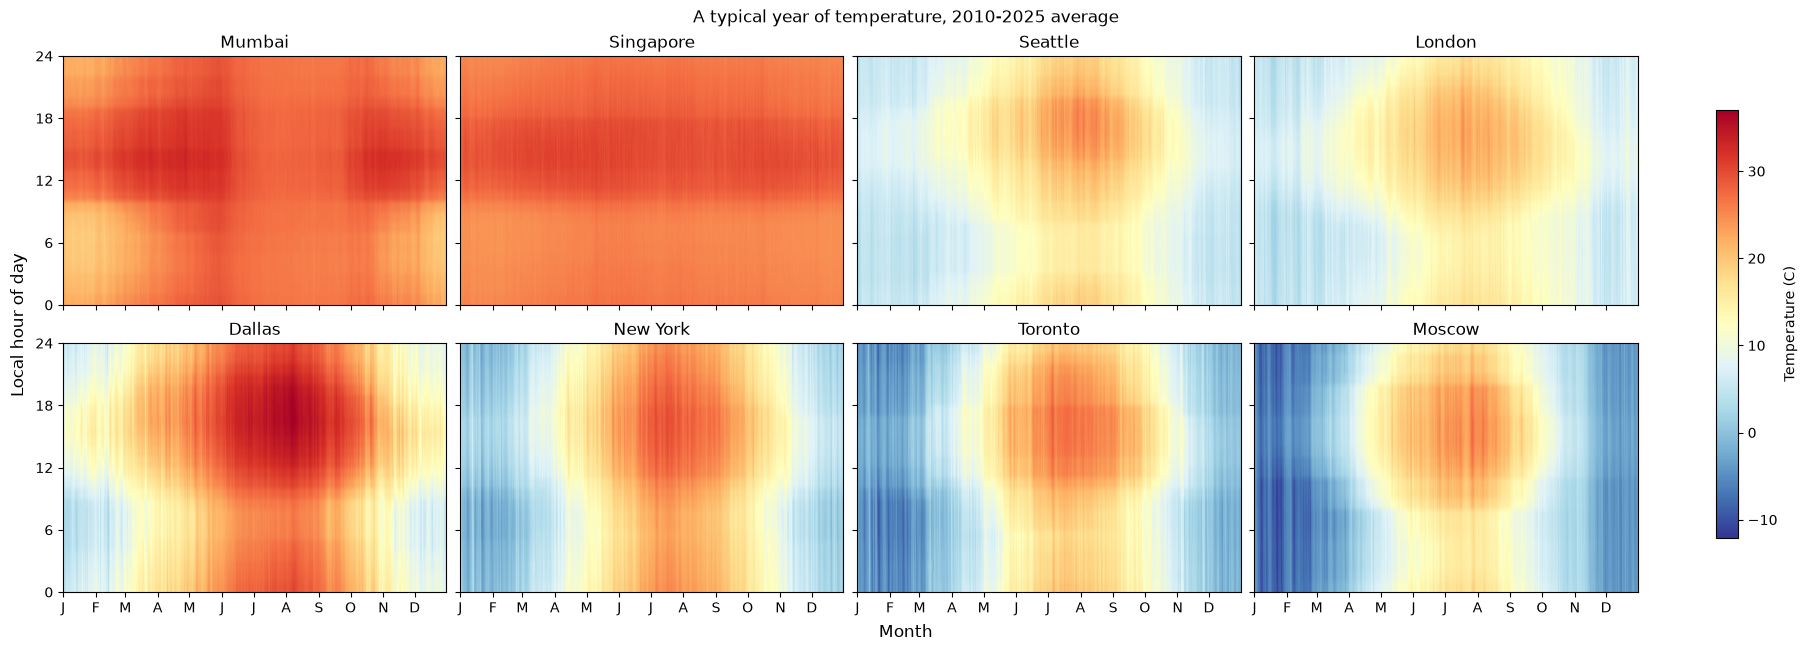

In [13]:
def load_hourly(city_row):
    files = sorted(RAW_DIR.glob(f"{city_row.slug}_*.parquet"))
    h = pd.concat([pd.read_parquet(f, columns=["time", "temperature_2m"]) for f in files])
    h = h.drop_duplicates("time").sort_values("time")
    local = h["time"].dt.tz_convert(city_row.tz)
    folded_doy = local.dt.dayofyear - ((local.dt.is_leap_year) & (local.dt.month > 2)).astype(int)
    return pd.DataFrame({
        "year": local.dt.year.values,
        "doy": folded_doy.clip(1, 365).values,
        "hour": local.dt.hour.values,
        "t": h["temperature_2m"].values,
    })


def carpet_matrix(city_row):
    h = load_hourly(city_row)
    h = h[(h["year"] >= CARPET_YEARS[0]) & (h["year"] <= CARPET_YEARS[1])]
    return h.groupby(["hour", "doy"])["t"].mean().unstack("doy")      # 24 x 365


sel = cities.set_index("city").loc[CARPET_CITIES].reset_index()
mats = {r.city: carpet_matrix(r) for r in sel.itertuples()}
vmin = min(m.min().min() for m in mats.values())
vmax = max(m.max().max() for m in mats.values())

ncols = 4
nrows = int(np.ceil(len(mats) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows),
                         sharex=True, sharey=True, squeeze=False, layout="constrained")
month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
for ax, (name, m) in zip(axes.ravel(), mats.items()):
    im = ax.imshow(m.values, aspect="auto", origin="lower", extent=[1, 365, 0, 24],
                   cmap="RdYlBu_r", vmin=vmin, vmax=vmax)
    ax.set_title(name)
    ax.set_xticks(month_starts)
    ax.set_xticklabels(list("JFMAMJJASOND"))
    ax.set_yticks([0, 6, 12, 18, 24])
for ax in axes.ravel()[len(mats):]:
    ax.axis("off")
fig.supxlabel("Month")
fig.supylabel("Local hour of day")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Temperature (C)", shrink=0.8)
fig.suptitle(f"A typical year of temperature, {CARPET_YEARS[0]}-{CARPET_YEARS[1]} average")
fig.savefig(FIG_DIR / "carpets.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.2 How often are big day-to-day jumps? (tail plot)

For each city, the share of days where the high (left) or low (right) changed by at least a given number of degrees from the day before. The y-axis is logarithmic so the rare, large jumps are visible. A curve that stays high and flattens to the right belongs to a volatile city. Grey lines are the other cities.

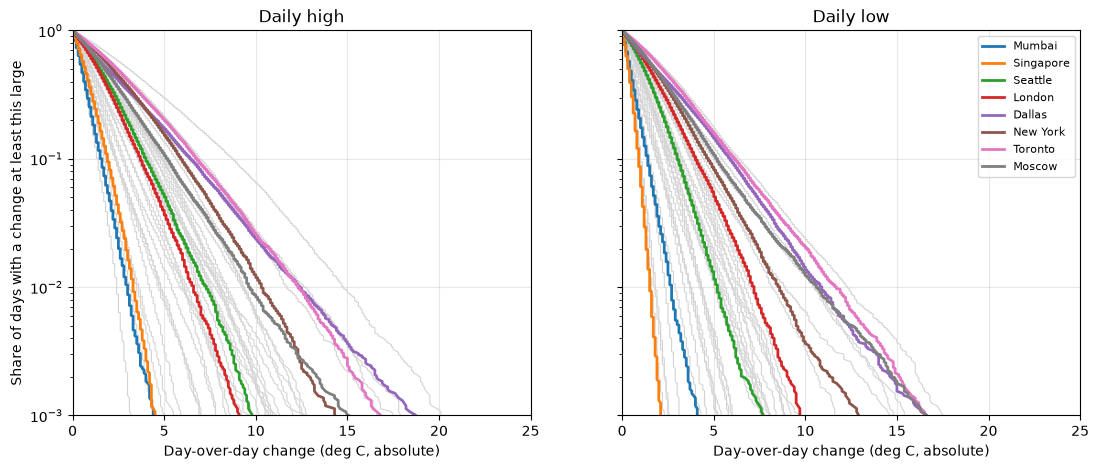

In [14]:
def exceedance(values):
    v = np.sort(values.dropna().abs().values)
    p = 1 - np.arange(len(v)) / len(v)
    return v, p


fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, v in zip(axes, ["tmax", "tmin"]):
    for city, g in d.groupby("city"):
        if city not in CARPET_CITIES:
            x, p = exceedance(g[f"{v}_d1"])
            ax.plot(x, p, color="lightgray", lw=0.8)
    for i, city in enumerate(CARPET_CITIES):
        x, p = exceedance(d.loc[d["city"] == city, f"{v}_d1"])
        ax.plot(x, p, lw=2, label=city, color=plt.cm.tab10(i % 10))
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 1)
    ax.set_xlim(0, 25)
    ax.set_xlabel("Day-over-day change (deg C, absolute)")
    ax.set_title(f"Daily {'high' if v == 'tmax' else 'low'}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Share of days with a change at least this large")
axes[1].legend(fontsize=8, loc="upper right")
fig.savefig(FIG_DIR / "day_over_day_tails.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.3 Variability fingerprint

Each bubble is a city. Right = bigger yearly swing, up = bigger day-to-day jumps in the daily high, bubble size = diurnal range, colour = climate group. It puts all three time scales on one chart.

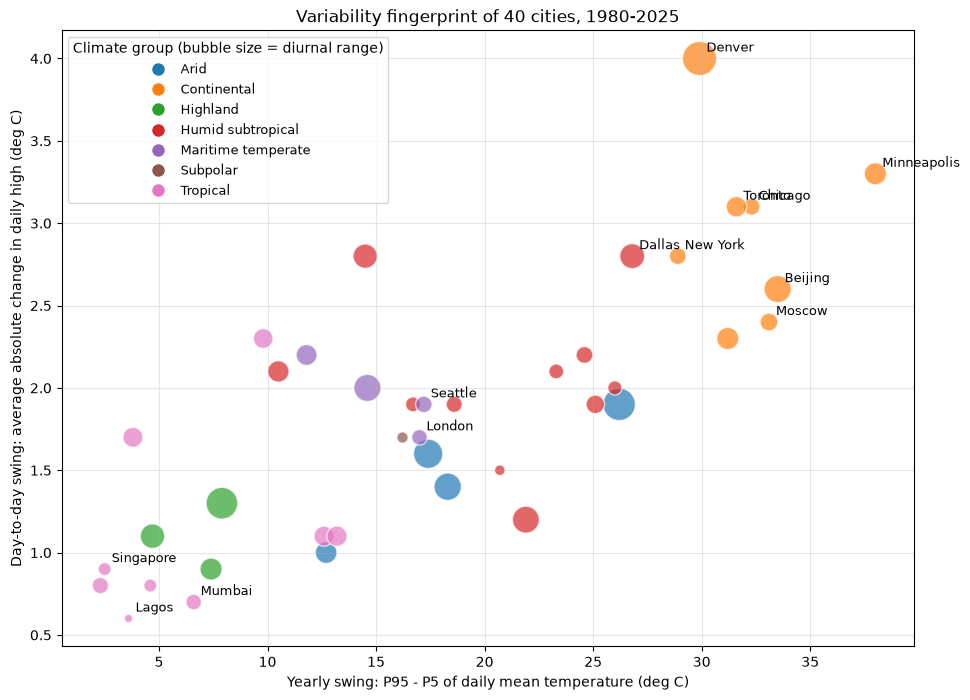

In [15]:
fp = summary.reset_index()

label_set = set(CARPET_CITIES)
label_set |= set(fp.nlargest(3, "annual_p95_p5")["city"])
label_set |= set(fp.nlargest(3, "dod_abs_tmax")["city"])
label_set |= set(fp.nsmallest(2, "dod_abs_tmax")["city"])

fig, ax = plt.subplots(figsize=(11, 8))
for grp, g in fp.groupby("group"):
    ax.scatter(g["annual_p95_p5"], g["dod_abs_tmax"], s=g["dtr_mean"] ** 2 * 3,
               color=group_colors[grp], alpha=0.7, edgecolor="white")
for _, r in fp.iterrows():
    if r["city"] in label_set:
        ax.annotate(r["city"], (r["annual_p95_p5"], r["dod_abs_tmax"]),
                    xytext=(5, 5), textcoords="offset points", fontsize=9)
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=group_colors[g],
                  markersize=10, label=g) for g in sorted(group_colors)]
ax.legend(handles=handles, title="Climate group (bubble size = diurnal range)", fontsize=9)
ax.set_xlabel("Yearly swing: P95 - P5 of daily mean temperature (deg C)")
ax.set_ylabel("Day-to-day swing: average absolute change in daily high (deg C)")
ax.set_title("Variability fingerprint of 40 cities, 1980-2025")
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "fingerprint.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.4 Seasonal cycle with spread

For each calendar day, the median daily mean temperature (line) and the 5th-95th percentile across all 46 years (band). A wide band means the weather on that date varies a lot from year to year. All panels share one y-axis.

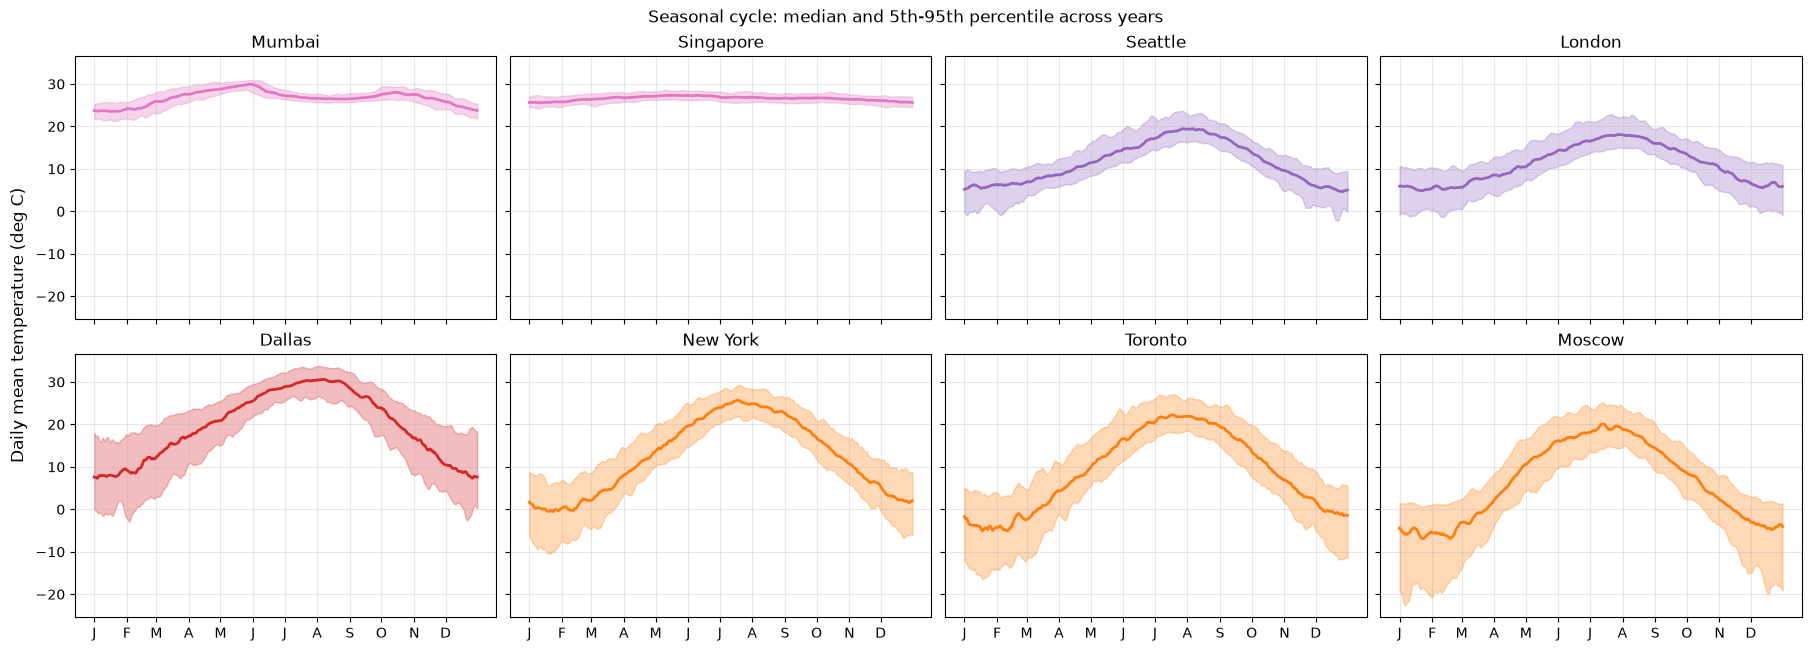

In [16]:
d["doy"] = (d["date"].dt.dayofyear - ((d["date"].dt.is_leap_year) & (d["date"].dt.month > 2)).astype(int)).clip(1, 365)
bands = d.groupby(["city", "doy"])["tmean"].quantile([0.05, 0.5, 0.95]).unstack()


def smooth_circular(s, w=7):
    ext = pd.concat([s.iloc[-w:], s, s.iloc[:w]])
    return pd.Series(ext.rolling(w, center=True).mean().iloc[w:-w].values, index=s.index)


nrows = int(np.ceil(len(CARPET_CITIES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows),
                         sharex=True, sharey=True, squeeze=False, layout="constrained")
for ax, city in zip(axes.ravel(), CARPET_CITIES):
    b = bands.loc[city]
    lo, med, hi = (smooth_circular(b[q]) for q in (0.05, 0.5, 0.95))
    ax.fill_between(b.index, lo, hi, alpha=0.3, color=group_colors[city_group[city]])
    ax.plot(b.index, med, color=group_colors[city_group[city]], lw=2)
    ax.set_title(city)
    ax.set_xticks(month_starts)
    ax.set_xticklabels(list("JFMAMJJASOND"))
    ax.grid(alpha=0.3)
for ax in axes.ravel()[len(CARPET_CITIES):]:
    ax.axis("off")
fig.supylabel("Daily mean temperature (deg C)")
fig.suptitle("Seasonal cycle: median and 5th-95th percentile across years")
fig.savefig(FIG_DIR / "seasonal_bands.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.5 Diurnal range by month

Average daily high-minus-low for every city and month, cities grouped by climate type. Shows which cities have a big daily swing all year (deserts, highlands) and which only in summer or winter.

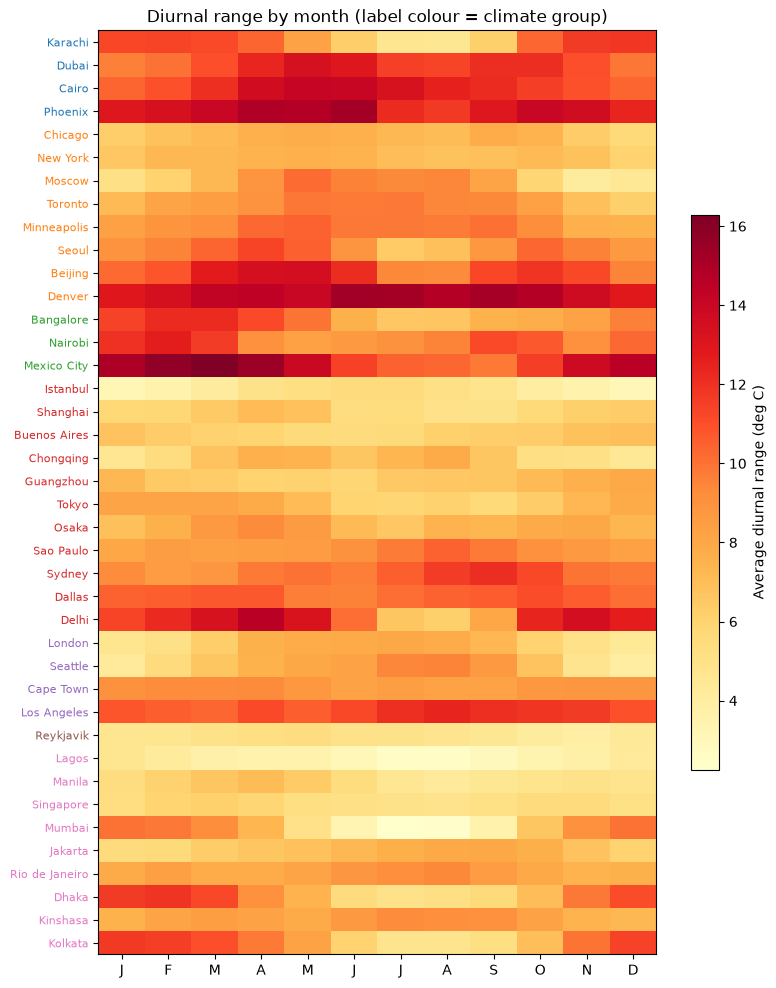

In [17]:
order = summary.reset_index().sort_values(["group", "dtr_mean"])["city"].tolist()
dm = dtr_month.loc[order]

fig, ax = plt.subplots(figsize=(9, 12))
im = ax.imshow(dm.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)
for tick, city in zip(ax.get_yticklabels(), order):
    tick.set_color(group_colors[city_group[city]])
ax.set_xticks(range(12))
ax.set_xticklabels(list("JFMAMJJASOND"))
fig.colorbar(im, ax=ax, label="Average diurnal range (deg C)", shrink=0.6)
ax.set_title("Diurnal range by month (label colour = climate group)")
fig.savefig(FIG_DIR / "dtr_month_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Has variability changed since 1980?

For each city and metric we have one value per year (46 points). Two simple ways to measure change:

- **Theil-Sen slope:** the median of all pairwise slopes, a trend line that a few extreme years cannot drag around. Reported per decade, with a Kendall rank-correlation p-value for "is there any monotonic trend at all?".
- **Early vs late:** the average of 1980-1989 compared with 2016-2025.

**Cautions:** with 40 cities x 6 metrics = 240 tests, about 12 will look "significant" at the 5% level by chance alone, so look for patterns across many cities rather than single hits. ERA5 also assimilates different observations over time (many more satellites after ~2000), which can introduce small artificial trends in variability. Treat these as indicative, and use the station check in section 9 as a cross-check.

In [18]:
from scipy import stats

TREND_METRICS = ["dtr_mean", "dod_abs_tmax", "dod_abs_tmin",
                 "swing48_days_any", "annual_p95_p5", "annual_extreme_range"]
EARLY, LATE = (1980, 1989), (2016, 2025)

rows = []
for city, g in annual.groupby("city"):
    g = g.sort_values("year")
    for m in TREND_METRICS:
        gm = g.dropna(subset=[m])
        slope, intercept, lo, hi = stats.theilslopes(gm[m].values, gm["year"].values)
        tau, p = stats.kendalltau(gm["year"].values, gm[m].values)
        early = g.loc[g["year"].between(*EARLY), m].mean()
        late = g.loc[g["year"].between(*LATE), m].mean()
        rows.append(dict(city=city, metric=m, slope_per_decade=slope * 10,
                         ci_low=lo * 10, ci_high=hi * 10, p_value=p,
                         early=early, late=late, delta=late - early))

trends = pd.DataFrame(rows).merge(cities[["city", "group"]], on="city")
trends["significant"] = trends["p_value"] < 0.05

trend_summary = trends.groupby("metric").agg(
    median_slope_per_decade=("slope_per_decade", "median"),
    pct_cities_increasing=("slope_per_decade", lambda s: (s > 0).mean() * 100),
    pct_cities_significant=("significant", lambda s: s.mean() * 100),
    median_delta_late_vs_early=("delta", "median"),
).loc[TREND_METRICS].round(2)
trend_summary

,median_slope_per_decade,pct_cities_increasing,pct_cities_significant,median_delta_late_vs_early
metric,,,,
dtr_mean,0.01,52.5,60.0,-0.03
dod_abs_tmax,0.01,72.5,40.0,0.05
dod_abs_tmin,-0.01,35.0,52.5,-0.03
swing48_days_any,-0.00,35.0,22.5,0.00
annual_p95_p5,0.06,57.5,22.5,0.11
annual_extreme_range,0.06,57.5,25.0,-0.09


### 8.1 Change by city and metric (late minus early)

Each cell shows the change in the metric's units between 1980-1989 and 2016-2025 (an asterisk marks a significant Theil-Sen/Kendall trend at p < 0.05). Colour shows the change relative to how much that metric changes across cities, so all columns are comparable: red = more variable, blue = less.

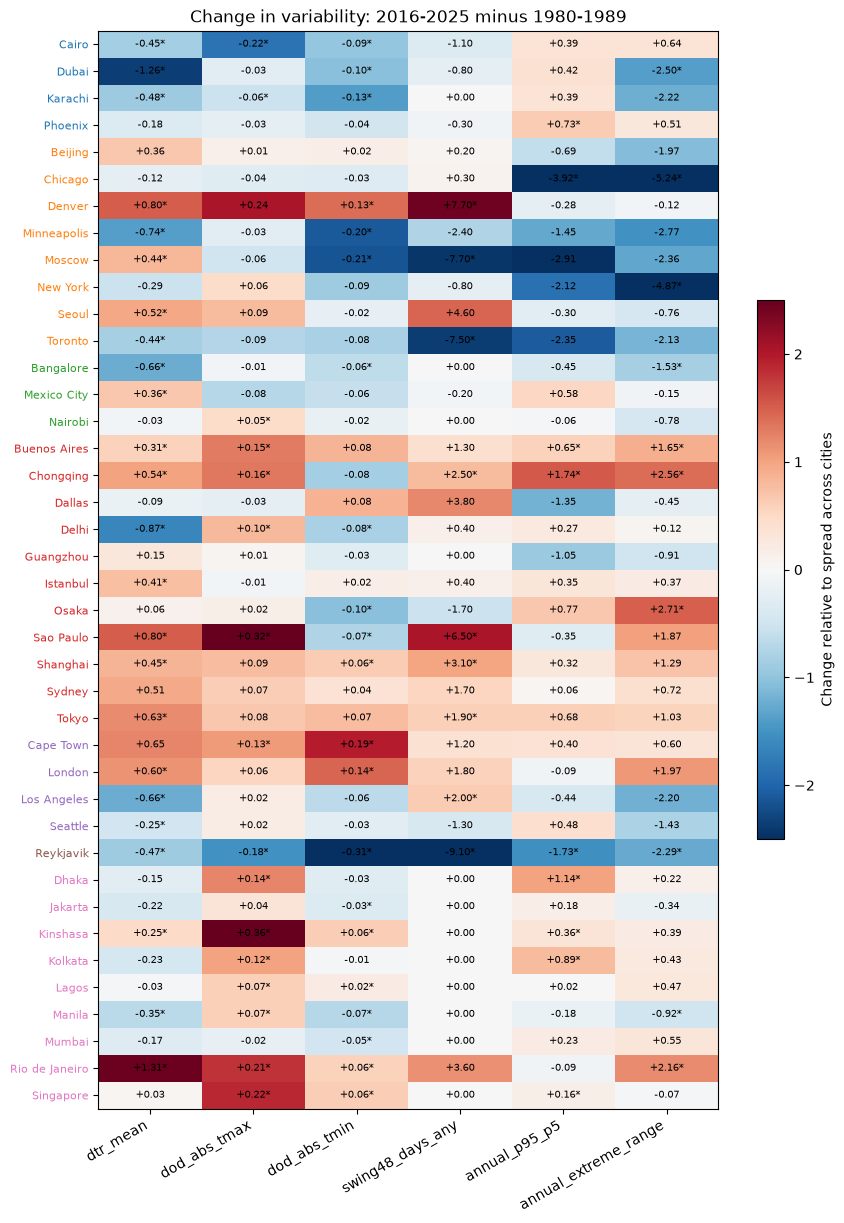

In [19]:
delta = trends.pivot(index="city", columns="metric", values="delta")[TREND_METRICS]
sig = trends.pivot(index="city", columns="metric", values="significant")[TREND_METRICS]

order = cities.sort_values(["group", "city"])["city"].tolist()
delta, sig = delta.loc[order], sig.loc[order]
z = delta / delta.std()

fig, ax = plt.subplots(figsize=(10, 14))
im = ax.imshow(z.values, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        star = "*" if sig.iloc[i, j] else ""
        ax.text(j, i, f"{delta.iloc[i, j]:+.2f}{star}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(len(TREND_METRICS)))
ax.set_xticklabels(TREND_METRICS, rotation=30, ha="right")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)
for tick, city in zip(ax.get_yticklabels(), order):
    tick.set_color(group_colors[city_group[city]])
ax.set_title(f"Change in variability: {LATE[0]}-{LATE[1]} minus {EARLY[0]}-{EARLY[1]}")
fig.colorbar(im, ax=ax, shrink=0.5, label="Change relative to spread across cities")
fig.savefig(FIG_DIR / "trend_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.2 Trend lines for selected cities

Yearly values (grey) with the Theil-Sen trend line (red) and the slope per decade in each title.

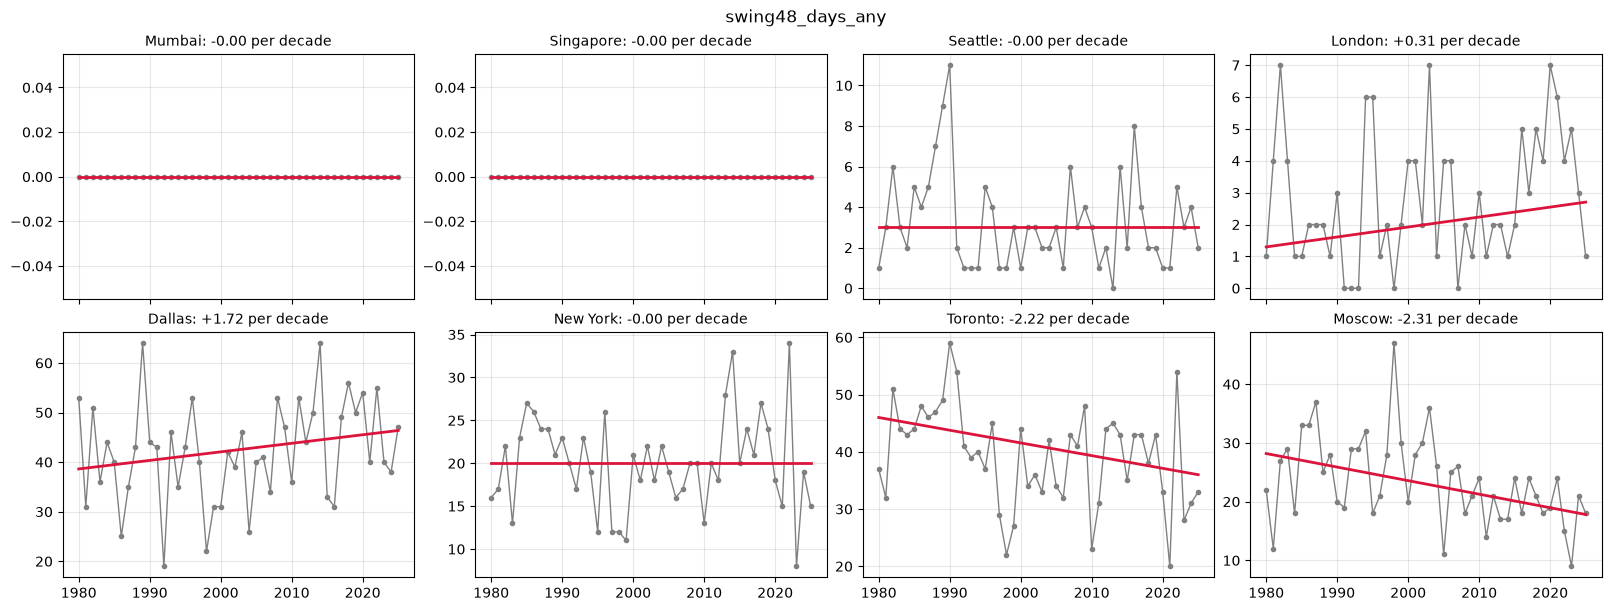

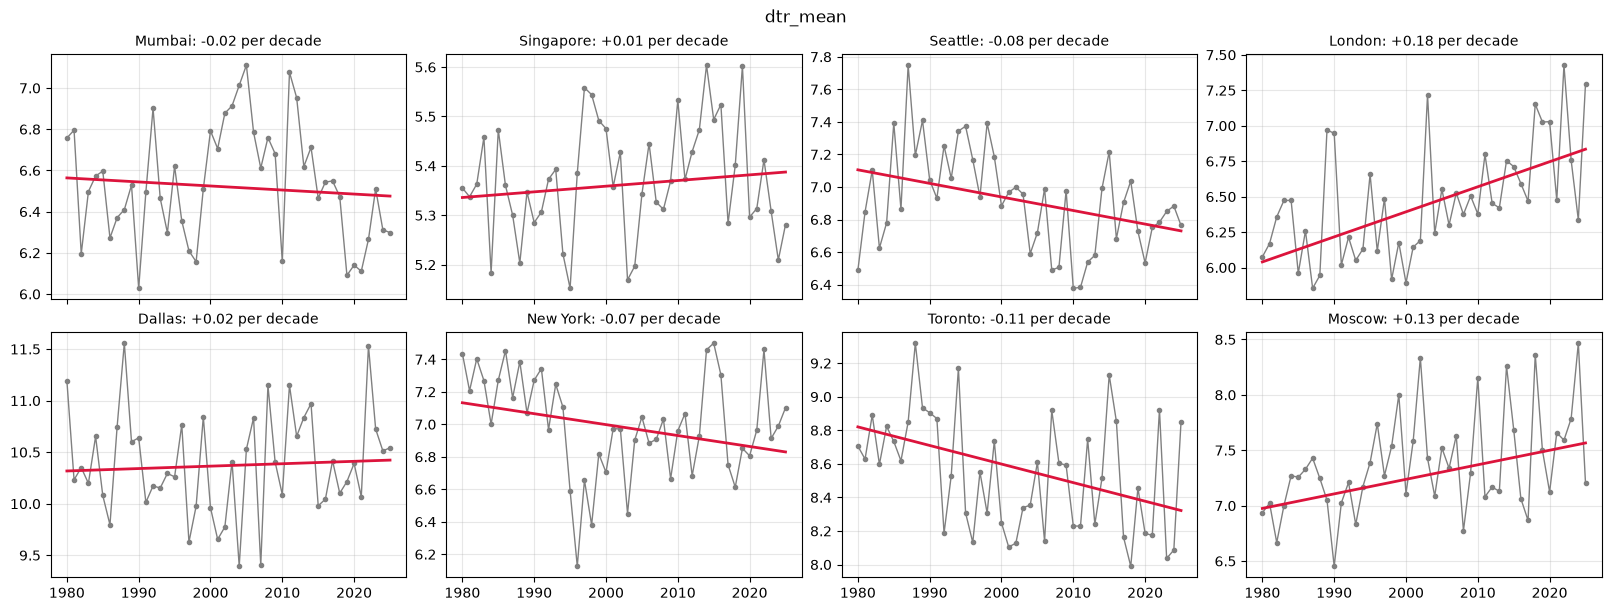

In [20]:
def plot_trend(metric, city_list, ncols=4):
    n = len(city_list)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows),
                             sharex=True, squeeze=False, layout="constrained")
    for ax, city in zip(axes.ravel(), city_list):
        g = annual[annual["city"] == city].sort_values("year").dropna(subset=[metric])
        slope, icpt = stats.theilslopes(g[metric].values, g["year"].values)[:2]
        ax.plot(g["year"], g[metric], marker="o", ms=3, lw=1, color="gray")
        ax.plot(g["year"], icpt + slope * g["year"], color="crimson", lw=2)
        ax.set_title(f"{city}: {slope * 10:+.2f} per decade", fontsize=10)
        ax.grid(alpha=0.3)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle(metric)
    return fig


fig = plot_trend("swing48_days_any", CARPET_CITIES)
fig.savefig(FIG_DIR / "trend_swing_days.png", dpi=150, bbox_inches="tight")
plt.show()

fig = plot_trend("dtr_mean", CARPET_CITIES)
fig.savefig(FIG_DIR / "trend_dtr.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Validation against weather stations

ERA5 is a model, on a ~25 km grid, with hourly output. Real airport stations record continuous highs and lows at a point. Two differences to expect: ERA5's daily high is the highest *hourly* value (slightly under the true peak), and a grid cell smooths local extremes. So ERA5 will tend to **understate** the diurnal range and the biggest swings. The question is by how much, and whether city rankings survive.

Source: NOAA GHCN-Daily (daily highs and lows per station, quality-flagged values only). Station IDs below are US airports and Central Park; if one fails to download or looks wrong, check its ID in NOAA's `ghcnd-stations.txt` file. Days where the station has no value are removed from both series so the comparison is like-for-like.

In [21]:
VALIDATION_STATIONS = {
    "Seattle": "USW00024233",       # Seattle-Tacoma Intl Airport
    "Dallas": "USW00003927",        # Dallas/Fort Worth Intl Airport
    "New York": "USW00094728",      # Central Park
    "Chicago": "USW00094846",       # O'Hare Intl Airport
    "Denver": "USW00003017",        # Denver Intl Airport
    "Phoenix": "USW00023183",       # Phoenix Sky Harbor
    "Minneapolis": "USW00014922",   # Minneapolis-St Paul Intl Airport
    "Los Angeles": "USW00023174",   # Los Angeles Intl Airport
}
GHCN_URL = "https://www.ncei.noaa.gov/pub/data/ghcn/daily/by_station/{sid}.csv.gz"
VAL_DIR = DATA_DIR / "validation"
VAL_DIR.mkdir(parents=True, exist_ok=True)


def load_ghcn(station_id):
    path = VAL_DIR / f"{station_id}.csv.gz"
    if not path.exists():
        r = requests.get(GHCN_URL.format(sid=station_id), timeout=180)
        r.raise_for_status()
        path.write_bytes(r.content)
    raw = pd.read_csv(path, header=None, dtype={"date": str},
                      names=["id", "date", "element", "value", "m_flag", "q_flag", "s_flag", "obs_time"],
                      usecols=["date", "element", "value", "q_flag"])
    raw = raw[raw["element"].isin(["TMAX", "TMIN"]) & raw["q_flag"].isna()]
    st = raw.pivot_table(index="date", columns="element", values="value", aggfunc="first") / 10   # tenths of C
    st.index = pd.to_datetime(st.index, format="%Y%m%d")
    return st.rename(columns={"TMAX": "st_tmax", "TMIN": "st_tmin"})


def compare_city(city):
    st = load_ghcn(VALIDATION_STATIONS[city])
    era = d[d["city"] == city].set_index("date")[["tmax", "tmin"]]
    j = era.join(st[["st_tmax", "st_tmin"]], how="left")
    ok = j[["st_tmax", "st_tmin"]].notna().all(axis=1)
    j.loc[~ok, :] = np.nan            # same days in both series
    return j.asfreq("D")              # keeps days consecutive so differences are valid


def variability_metrics(tmax, tmin):
    d1 = tmax.diff().abs()
    chg2_max = (tmax - tmax.shift(2)).abs()
    chg2_min = (tmin - tmin.shift(2)).abs()
    valid2 = chg2_max.notna() & chg2_min.notna()
    big = (chg2_max >= SWING_C) | (chg2_min >= SWING_C)
    year = tmax.index.year
    extreme = (tmax.groupby(year).max() - tmin.groupby(year).min()).mean()
    return {
        "dtr_mean": (tmax - tmin).mean(),
        "dod_abs_tmax": d1.mean(),
        "dod_p95_tmax": d1.quantile(0.95),
        "swing48_days_any": (big & valid2).sum() / valid2.sum() * 365,
        "annual_extreme_range": extreme,
    }

In [22]:
val_rows, acc_rows = [], []
for city in VALIDATION_STATIONS:
    try:
        j = compare_city(city)
    except Exception as e:
        print(f"{city}: skipped ({e})")
        continue
    era_m = variability_metrics(j["tmax"], j["tmin"])
    stn_m = variability_metrics(j["st_tmax"], j["st_tmin"])
    for k in era_m:
        val_rows.append(dict(city=city, metric=k, era5=era_m[k], station=stn_m[k]))
    acc_rows.append(dict(city=city, days=int(j["tmax"].notna().sum()),
                         tmax_bias=(j["tmax"] - j["st_tmax"]).mean(), tmax_corr=j["tmax"].corr(j["st_tmax"]),
                         tmin_bias=(j["tmin"] - j["st_tmin"]).mean(), tmin_corr=j["tmin"].corr(j["st_tmin"])))

validation = pd.DataFrame(val_rows)
validation["era5_minus_station"] = validation["era5"] - validation["station"]
validation["pct_diff"] = validation["era5_minus_station"] / validation["station"] * 100

print("Day-level accuracy (bias = ERA5 minus station, deg C):")
print(pd.DataFrame(acc_rows).round(2).to_string(index=False))
print()
print("Variability metrics, ERA5 vs station (pct_diff < 0 means ERA5 understates variability):")
validation.pivot(index="city", columns="metric", values="pct_diff").round(1)

C:\Users\samik\AppData\Local\Temp\ipykernel_3128\2741210921.py:22: DtypeWarning: Columns (5: q_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(path, header=None, dtype={"date": str},
C:\Users\samik\AppData\Local\Temp\ipykernel_3128\2741210921.py:22: DtypeWarning: Columns (5: q_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(path, header=None, dtype={"date": str},
C:\Users\samik\AppData\Local\Temp\ipykernel_3128\2741210921.py:22: DtypeWarning: Columns (5: q_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(path, header=None, dtype={"date": str},
C:\Users\samik\AppData\Local\Temp\ipykernel_3128\2741210921.py:22: DtypeWarning: Columns (5: q_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(path, header=None, dtype={"date": str},
C:\Users\samik\AppData\Local\Temp\ipykernel_3128\2741210921.

Day-level accuracy (bias = ERA5 minus station, deg C):
       city  days  tmax_bias  tmax_corr  tmin_bias  tmin_corr
    Seattle 16800      -0.62       0.99       0.74       0.97
     Dallas 16801      -0.49       0.99       0.65       0.99
   New York 16801      -1.26       0.99      -0.14       0.99
    Chicago 16801      -1.82       0.99       1.15       0.99
     Denver 11016      -0.53       0.99       0.61       0.97
    Phoenix 16801      -0.52       0.99      -0.95       0.99
Minneapolis 16801      -0.66       1.00      -0.03       0.99
Los Angeles 16797       3.01       0.84      -0.50       0.96

Variability metrics, ERA5 vs station (pct_diff < 0 means ERA5 understates variability):


metric,annual_extreme_range,dod_abs_tmax,dod_p95_tmax,dtr_mean,swing48_days_any
city,,,,,
Chicago,-6.3,-11.5,-11.6,-29.7,-33.0
Dallas,-4.3,-7.7,-7.9,-9.9,-11.7
Denver,-5.9,-8.7,-10.3,-7.3,-23.2
Los Angeles,20.7,11.6,-5.4,45.0,-32.4
Minneapolis,-0.6,-5.3,-3.4,-6.4,-9.4
New York,-0.4,-13.8,-17.0,-13.8,-43.1
Phoenix,2.2,-2.4,-3.6,3.3,-18.1
Seattle,-7.7,-16.7,-16.4,-16.4,-62.8


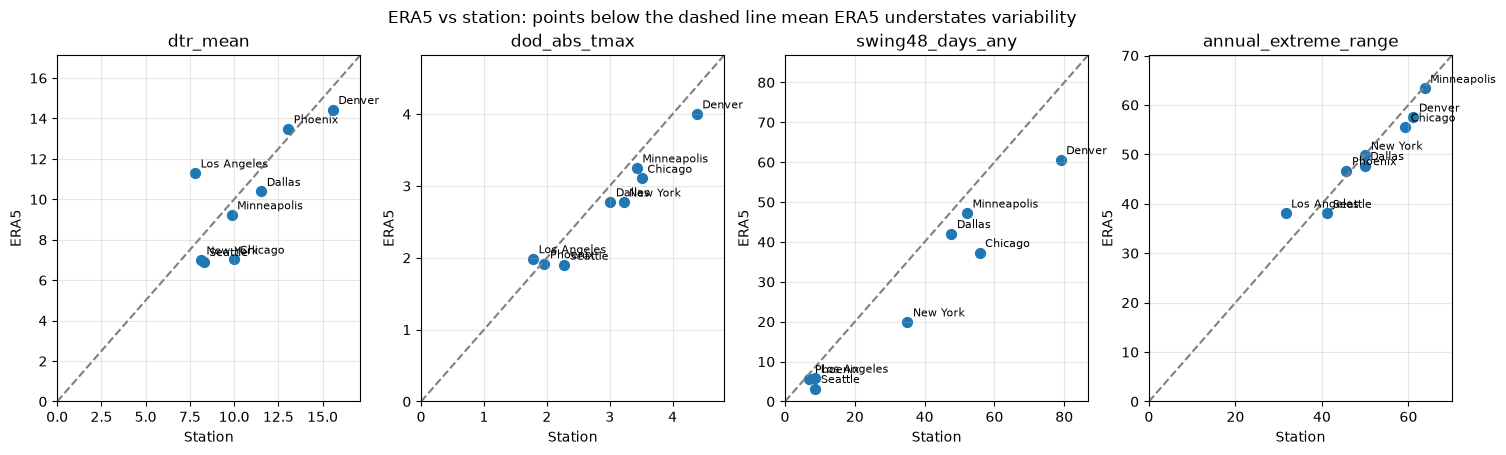

In [23]:
metric_list = ["dtr_mean", "dod_abs_tmax", "swing48_days_any", "annual_extreme_range"]
fig, axes = plt.subplots(1, len(metric_list), figsize=(4.5 * len(metric_list), 4.5), squeeze=False)
for ax, m in zip(axes[0], metric_list):
    v = validation[validation["metric"] == m]
    ax.scatter(v["station"], v["era5"], s=50)
    for _, r in v.iterrows():
        ax.annotate(r["city"], (r["station"], r["era5"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    lim = [0, max(v["station"].max(), v["era5"].max()) * 1.1]
    ax.plot(lim, lim, color="gray", ls="--")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("Station")
    ax.set_ylabel("ERA5")
    ax.set_title(m)
    ax.grid(alpha=0.3)
fig.suptitle("ERA5 vs station: points below the dashed line mean ERA5 understates variability")
fig.savefig(FIG_DIR / "validation_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## Reading the results

- If ERA5 understates the metrics by a similar proportion in every city, rankings and trends are still trustworthy even if absolute numbers are a bit low.
- If the gap varies a lot by city (for example coastal Los Angeles vs inland Denver), be careful comparing absolute values across cities of different geography.
- For the final write-up, state the ERA5 grid resolution and this validation result alongside the headline numbers.